# Sales Forecasting — Regional Retail (synthetic data)
Monthly revenue forecast built on the SQLite database in `data/sales.db`. **Data is synthetic** (see `generate_data.py`).

Plan: aggregate with SQL → compare a seasonal-naive baseline, Holt-Winters and SARIMA on a 6-month holdout → forecast the next 12 months → forecast each region.

In [1]:
import sqlite3, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings('ignore'); plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
con=sqlite3.connect('../data/sales.db')
con.executescript(open('../sql/kpi_queries.sql').read().split('-- Q01')[0])
monthly=pd.read_sql("SELECT ym, SUM(revenue) revenue FROM v_sales GROUP BY ym ORDER BY ym",con)
monthly['ym']=pd.PeriodIndex(monthly.ym,freq='M'); s=monthly.set_index('ym').revenue
print(len(s),'months,',s.index.min(),'to',s.index.max()); s.tail()

36 months, 2023-01 to 2025-12


ym
2025-08    8.566188e+06
2025-09    7.235940e+06
2025-10    6.669421e+06
2025-11    8.476695e+06
2025-12    8.410870e+06
Freq: M, Name: revenue, dtype: float64

## 1. Train / holdout split
Hold out the last 6 months so every model is scored on data it has not seen.

In [2]:
H=6; train,test=s.iloc[:-H],s.iloc[-H:]
def mape(a,f): return float(np.mean(np.abs((a-f)/a))*100)
def rmse(a,f): return float(np.sqrt(np.mean((a-f)**2)))
preds={}
# baseline: same month last year, scaled by trailing YoY growth
yoy=train.iloc[-12:].sum()/train.iloc[-24:-12].sum()
preds['Seasonal naive (x YoY)']=pd.Series([train[p-12]*yoy for p in test.index],index=test.index)
hw=ExponentialSmoothing(train,trend='add',seasonal='mul',seasonal_periods=12).fit()
preds['Holt-Winters']=pd.Series(hw.forecast(H).values,index=test.index)
sm=SARIMAX(train,order=(1,1,1),seasonal_order=(0,1,0,12)).fit(disp=False)
preds['SARIMA(1,1,1)(0,1,0,12)']=pd.Series(sm.forecast(H).values,index=test.index)
res=pd.DataFrame({k:{'MAPE %':mape(test,v),'RMSE':rmse(test,v)} for k,v in preds.items()}).T.round(2)
res

,MAPE %,RMSE
Seasonal naive (x YoY),0.72,87296.42
Holt-Winters,1.22,119093.38
"SARIMA(1,1,1)(0,1,0,12)",1.40,126622.23


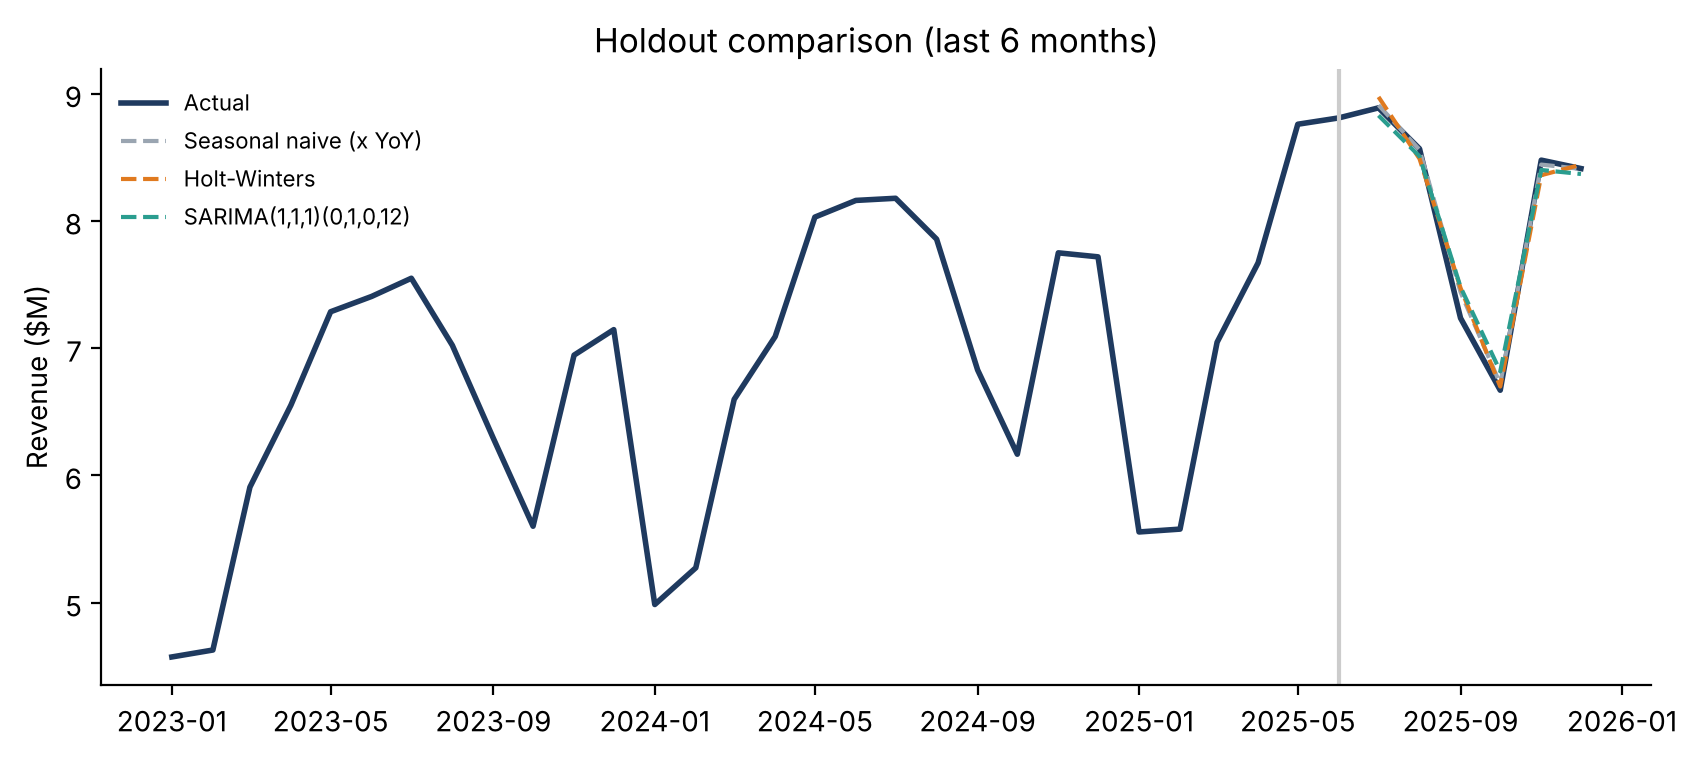

In [3]:
fig,ax=plt.subplots(); ax.plot(s.index.to_timestamp(),s.values/1e6,color='#1f3a5f',lw=2,label='Actual')
for (k,v),c in zip(preds.items(),['#9aa5b1','#e07a1f','#2a9d8f']): ax.plot(v.index.to_timestamp(),v.values/1e6,'--',color=c,label=k)
ax.axvline(train.index[-1].to_timestamp(),color='#ccc'); ax.set_ylabel('Revenue ($M)'); ax.set_title('Holdout comparison (last 6 months)'); ax.legend(frameon=False,fontsize=8); plt.show()

## 2. Pick the best model and forecast 12 months
The lower-MAPE of the two statistical models is refit on all 36 months (the naive model is only a benchmark; synthetic seasonality is perfectly repeatable, so it is hard to beat here — on real data it usually is not). Prediction intervals come from the SARIMA model for context.

In [4]:
best=res.drop(index='Seasonal naive (x YoY)')['MAPE %'].idxmin(); print('Best statistical model on holdout:',best)
print('Seasonal naive MAPE',res.loc['Seasonal naive (x YoY)','MAPE %'],'is the benchmark to beat; on this smooth synthetic series it is hard to beat.')
F=12; idx=pd.period_range(s.index[-1]+1,periods=F,freq='M')
if best.startswith('Holt'):
    fit=ExponentialSmoothing(s,trend='add',seasonal='mul',seasonal_periods=12).fit(); point=fit.forecast(F).values
    resid=s-fit.fittedvalues; sd=resid.std(); lo,hi=point-1.28*sd,point+1.28*sd
else:
    fit=SARIMAX(s,order=(1,1,1),seasonal_order=(0,1,0,12)).fit(disp=False); fc=fit.get_forecast(F)
    point=fc.predicted_mean.values; ci=fc.conf_int(alpha=0.2).values; lo,hi=ci[:,0],ci[:,1]
fcst=pd.DataFrame({'month':idx.astype(str),'forecast':point,'lower_80':lo,'upper_80':hi}).round(0)
fcst.to_csv('../data/results/forecast_total.csv',index=False); fcst

Best statistical model on holdout: Holt-Winters
Seasonal naive MAPE 0.72 is the benchmark to beat; on this smooth synthetic series it is hard to beat.


,month,forecast,lower_80,upper_80
0,2026-01,5990978.0,5908850.0,6073106.0
1,2026-02,6126407.0,6044279.0,6208535.0
2,2026-03,7725751.0,7643624.0,7807879.0
3,2026-04,8407666.0,8325538.0,8489794.0
4,2026-05,9493280.0,9411152.0,9575408.0
5,2026-06,9597999.0,9515871.0,9680127.0
6,2026-07,9678453.0,9596325.0,9760580.0
7,2026-08,9217979.0,9135851.0,9300106.0
8,2026-09,7981225.0,7899097.0,8063353.0
9,2026-10,7228577.0,7146450.0,7310705.0


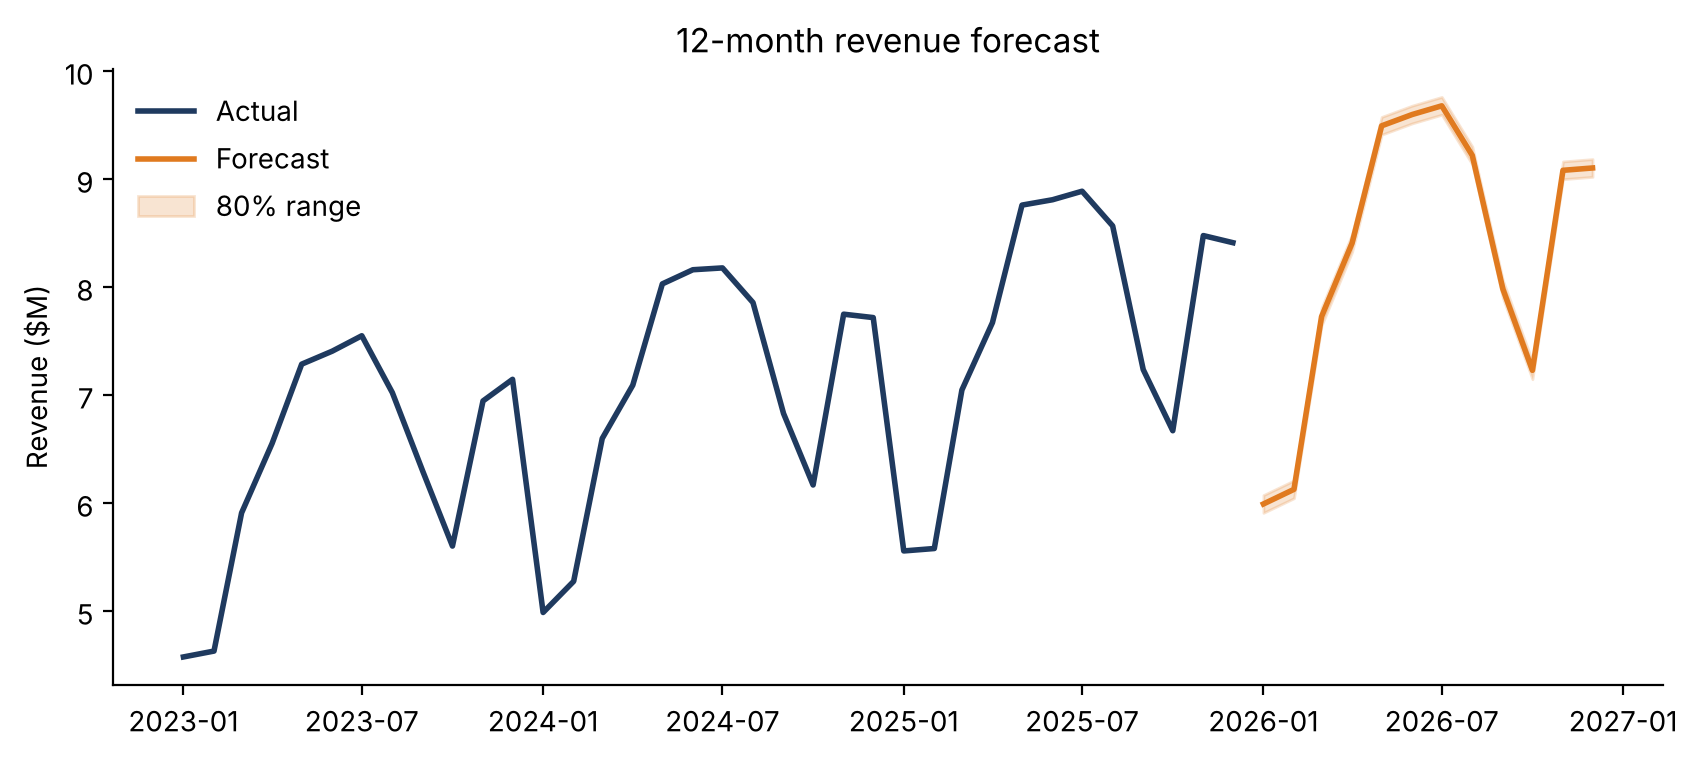

2025 actual: $91.7M | 2026 forecast: $99.6M (+8.7% YoY)


In [5]:
fig,ax=plt.subplots(); ax.plot(s.index.to_timestamp(),s.values/1e6,color='#1f3a5f',lw=2,label='Actual')
ax.plot(idx.to_timestamp(),point/1e6,color='#e07a1f',lw=2,label='Forecast'); ax.fill_between(idx.to_timestamp(),lo/1e6,hi/1e6,color='#e07a1f',alpha=.2,label='80% range')
ax.set_ylabel('Revenue ($M)'); ax.set_title('12-month revenue forecast'); ax.legend(frameon=False); plt.show()
print(f"2025 actual: ${s['2025'].sum()/1e6:.1f}M | 2026 forecast: ${point.sum()/1e6:.1f}M ({(point.sum()/s['2025'].sum()-1)*100:+.1f}% YoY)")

## 3. Forecast by region
Same approach per region (Holt-Winters, holdout MAPE reported) so targets can be set region by region and underperformers flagged.

In [6]:
rm=pd.read_sql("SELECT region_name, ym, SUM(revenue) revenue FROM v_sales GROUP BY region_name, ym",con); rm['ym']=pd.PeriodIndex(rm.ym,freq='M')
rows=[];out=[]
for reg,g in rm.groupby('region_name'):
    x=g.set_index('ym').revenue.sort_index(); tr,te=x.iloc[:-H],x.iloc[-H:]
    m=ExponentialSmoothing(tr,trend='add',seasonal='mul',seasonal_periods=12).fit(); mp=mape(te,pd.Series(m.forecast(H).values,index=te.index))
    f=ExponentialSmoothing(x,trend='add',seasonal='mul',seasonal_periods=12).fit().forecast(F).values
    rows.append({'region':reg,'2025 actual':x['2025'].sum(),'2026 forecast':f.sum(),'YoY %':(f.sum()/x['2025'].sum()-1)*100,'holdout MAPE %':mp})
    out+= [{'region':reg,'month':str(p),'forecast':v} for p,v in zip(idx,f)]
reg_tbl=pd.DataFrame(rows).round(1); pd.DataFrame(out).round(0).to_csv('../data/results/forecast_region.csv',index=False); reg_tbl

,region,2025 actual,2026 forecast,YoY %,holdout MAPE %
0,Central,5735836.5,4961128.9,-13.5,3.0
1,East,16351618.9,17563302.6,7.4,1.9
2,North,21343170.5,23664836.7,10.9,1.4
3,South,23009025.9,25228409.5,9.6,2.2
4,West,25225208.7,28090190.4,11.4,1.5


## 4. Takeaways
- Revenue is strongly seasonal (summer and Nov–Dec peaks); a seasonal model beats a flat trend.
- Central region is shrinking year over year and is the main target for a recovery plan.
- Always report holdout error next to a forecast — a forecast without its error is not decision-ready.